# Distributional models and ensemble uncertainty

**Objective:** distinguish conditional response variation, quantile intervals,
and disagreement between independently fitted predictors. Prerequisites:
[location and spread](../tutorials/changing_variability.rst) and the common
estimator workflow. Allow a few minutes on a CPU; the execution note records
actual runtime and versions. Training, early-stopping validation, and final
test rows are separate.

## Simulate changing response variability

For $Y\mid x\sim N(\mu(x),\sigma(x)^2)$, the mean need not determine the
spread. We generate a curved location and a positive varying scale so the
normal distribution's location and standard deviation have known meanings.

**Execution environment:** nampy 0.3.0, numpy 1.26.4, scikit-learn 1.9.0, torch 2.14.1+cpu, lightning 2.6.6. Python 3.12.13; source base commit `4cffdeb` (working checkout); elapsed 21.3 seconds on this CPU. Runtime varies by hardware.

In [1]:
import tempfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score

rng = np.random.default_rng(11)
X = pd.DataFrame({"x": rng.uniform(-1, 1, 1200)})
location = np.sin(3 * X.x)
scale = 0.12 + 0.35 * (X.x + 1) / 2
y = location + scale * rng.normal(size=len(X))
X_fit, X_test, y_fit, y_test = train_test_split(X, y, test_size=0.2, random_state=7)
X_train, X_val, y_train, y_val = train_test_split(X_fit, y_fit, test_size=0.25, random_state=8)
fit_options = dict(max_epochs=120, lr=0.01, batch_size=128, patience=20,
                   random_state=7, logger=False, enable_progress_bar=False,
                   enable_model_summary=False, checkpoint_path=tempfile.mkdtemp())


## Fit the complete conditional distribution

A normal observation contributes $\log\sigma+(y-\mu)^2/(2\sigma^2)$ plus
a constant to negative log likelihood. The model must explain residual spread
without simply inflating it everywhere. Natural-parameter transforms enforce
positive scale; this output constraint does not by itself ensure calibration.

In [2]:
from nampy.models import NAMLSS, QNAMLSS

normal = NAMLSS(family="normal", layer_sizes=[24, 12], dropout=0., numerical_preprocessing="minmax")
normal.fit(X_train, y_train, X_val=X_val, y_val=y_val, **fit_options)
parameters = normal.predict(X_test)
assert parameters.shape == (len(X_test), 2)
assert np.all(parameters[:, 1] > 0)
normal.predict_components(X_test).validate_additive_reconstruction(atol=1e-5)
normal.evaluate(X_test, y_test)


/home/ad32/projects/package/NAMpy/.venv/lib/python3.12/site-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(
/home/ad32/projects/package/NAMpy/nampy/models/_base.py:622: UserWarning: The given NumPy array is not writable, and PyTorch does not support non-writable tensors. This means writing to this tensor will result in undefined behavior. You may want to copy the array to protect its data or make it writable before converting it to a tensor. This type of warning will be suppressed for the rest of this program. (Triggered internally at /__w/pytorch/pytorch/torch/csrc/utils/tensor_numpy.cpp:213.)
  train_targets=torch.as_tensor(self.data_module.y_train),
GPU available: False, used: False


TPU available: False, using: 0 TPU cores


💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.


/home/ad32/projects/package/NAMpy/.venv/lib/python3.12/site-packages/lightning/pytorch/utilities/_pytree.py:21: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.
/home/ad32/projects/package/NAMpy/.venv/lib/python3.12/site-packages/lightning/pytorch/trainer/connectors/data_connector.py:434: The 'val_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=11` in the `DataLoader` to improve performance.
/home/ad32/projects/package/NAMpy/.venv/lib/python3.12/site-packages/lightning/pytorch/core/module.py:522: You called `self.log('val_loss', ..., logger=True)` but have no logger configured. You can enable one by doing `Trainer(logger=ALogger(...))`
/home/ad32/projects/package/NAMpy/.venv/lib/python3.12/site-packages/lightning/pytorch/trainer/connectors/data_connector.py:434: The 'train_dataloader' does not have many workers which may be a

`Trainer.fit` stopped: `max_epochs=120` reached.


{'NLL': 0.13164417445659637,
 'MSE': 0.09064392268702878,
 'MAE': 0.23055290961241953,
 'CRPS': 0.1636143167416218}

## Inspect location and conditional spread

The upper and lower curves describe response variation conditional on inputs;
they are not confidence bands for an estimated mean. The feature density shows
where observations inform the fit.

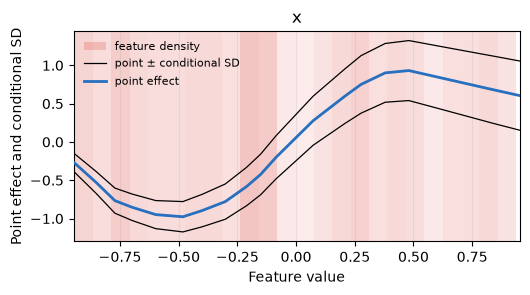

In [3]:
figures = normal.plot_distributional_effects(X_test, reference_X=X_train, feature_names=["x"])
plt.show()
plt.close("all")


## Compare quantile intervals on untouched data

The $\tau$-quantile minimizes pinball loss
$\rho_\tau(u)=u\{\tau-\mathbf{1}(u<0)\}$.
An ordered parameterization prevents crossing. It does not guarantee that an
interval covers its nominal proportion of future observations. Compare
coverage and width together, and check subgroups when enough data are available.

In [4]:
quantiles = QNAMLSS(layer_sizes=[24, 12], dropout=0., numerical_preprocessing="minmax",
                    distributional_kwargs={"quantiles": [0.1, 0.5, 0.9]})
quantiles.fit(X_train, y_train, X_val=X_val, y_val=y_val, **fit_options)
q = quantiles.predict(X_test)
assert np.all(np.diff(q, axis=1) >= -1e-6)
mu, sd = parameters.T
intervals = {"Normal 80%": (mu - 1.2815515655 * sd, mu + 1.2815515655 * sd),
             "Quantile 80%": (q[:, 0], q[:, 2])}
pd.DataFrame([{"Interval": name, "Test coverage": np.mean((y_test >= lo) & (y_test <= hi)),
               "Mean width": np.mean(hi-lo)} for name,(lo,hi) in intervals.items()])


GPU available: False, used: False


TPU available: False, using: 0 TPU cores


💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.


/home/ad32/projects/package/NAMpy/.venv/lib/python3.12/site-packages/lightning/pytorch/utilities/_pytree.py:21: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.
/home/ad32/projects/package/NAMpy/.venv/lib/python3.12/site-packages/lightning/pytorch/trainer/connectors/data_connector.py:434: The 'val_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=11` in the `DataLoader` to improve performance.
/home/ad32/projects/package/NAMpy/.venv/lib/python3.12/site-packages/lightning/pytorch/core/module.py:522: You called `self.log('val_loss', ..., logger=True)` but have no logger configured. You can enable one by doing `Trainer(logger=ALogger(...))`
/home/ad32/projects/package/NAMpy/.venv/lib/python3.12/site-packages/lightning/pytorch/trainer/connectors/data_connector.py:434: The 'train_dataloader' does not have many workers which may be a

`Trainer.fit` stopped: `max_epochs=120` reached.


,Interval,Test coverage,Mean width
0,Normal 80%,0.7750,0.739486
1,Quantile 80%,0.9125,1.071011


In the saved run, the quantile interval is wider and covers more than the
nominal 80% of test outcomes. That is conservative coverage, not evidence of
better calibration. The normal interval is narrower and closer to the nominal
coverage on this simulated normal problem. Neither result establishes behavior
on a different dataset; choose tuning criteria using validation data and
report final interval behavior on untouched test observations.

## Separate predictive spread from ensemble disagreement

Independent estimators can disagree because of initialization and data
resampling. Their response-scale average is the ensemble prediction, while
their standard deviation describes between-fit variation. It does not include
observation noise or automatically define a calibrated interval. With a
nonlinear link, averaging responses also differs from transforming the average
link predictor.

GPU available: False, used: False


TPU available: False, using: 0 TPU cores


💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.


/home/ad32/projects/package/NAMpy/.venv/lib/python3.12/site-packages/lightning/pytorch/utilities/_pytree.py:21: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.
/home/ad32/projects/package/NAMpy/.venv/lib/python3.12/site-packages/lightning/pytorch/trainer/connectors/data_connector.py:434: The 'val_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=11` in the `DataLoader` to improve performance.
/home/ad32/projects/package/NAMpy/.venv/lib/python3.12/site-packages/lightning/pytorch/core/module.py:522: You called `self.log('val_loss', ..., logger=True)` but have no logger configured. You can enable one by doing `Trainer(logger=ALogger(...))`
/home/ad32/projects/package/NAMpy/.venv/lib/python3.12/site-packages/lightning/pytorch/trainer/connectors/data_connector.py:434: The 'train_dataloader' does not have many workers which may be a

`Trainer.fit` stopped: `max_epochs=120` reached.


...

GPU available: False, used: False


TPU available: False, using: 0 TPU cores


💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.


/home/ad32/projects/package/NAMpy/.venv/lib/python3.12/site-packages/lightning/pytorch/utilities/_pytree.py:21: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.
/home/ad32/projects/package/NAMpy/.venv/lib/python3.12/site-packages/lightning/pytorch/trainer/connectors/data_connector.py:434: The 'val_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=11` in the `DataLoader` to improve performance.
/home/ad32/projects/package/NAMpy/.venv/lib/python3.12/site-packages/lightning/pytorch/core/module.py:522: You called `self.log('val_loss', ..., logger=True)` but have no logger configured. You can enable one by doing `Trainer(logger=ALogger(...))`
/home/ad32/projects/package/NAMpy/.venv/lib/python3.12/site-packages/lightning/pytorch/trainer/connectors/data_connector.py:434: The 'train_dataloader' does not have many workers which may be a

`Trainer.fit` stopped: `max_epochs=120` reached.


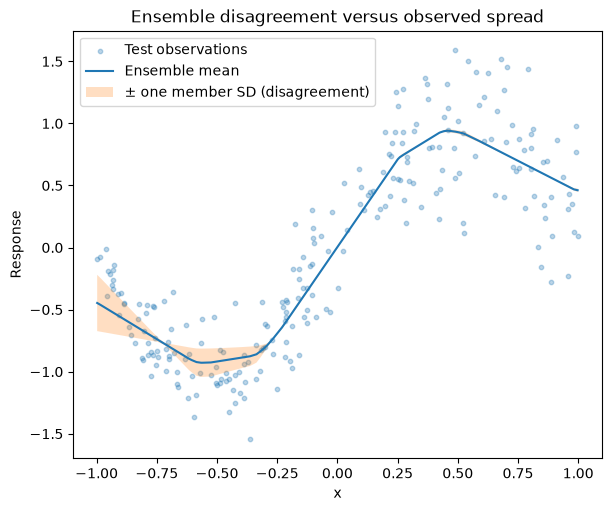

In [5]:
from nampy.models import NAMRegressor, NeuralEnsemble

ensemble = NeuralEnsemble(NAMRegressor(layer_sizes=[16, 8], dropout=0., numerical_preprocessing="minmax"),
                          n_estimators=3, random_state=17)
ensemble.fit(X_train, y_train, X_val=X_val, y_val=y_val, **fit_options)
uncertainty = ensemble.predict_component_uncertainty(X_test)
mean = uncertainty.mean.response
disagreement = uncertainty.response_std
order = np.argsort(X_test.x.to_numpy())
figure, axis = plt.subplots(figsize=(6, 5), constrained_layout=True)
axis.scatter(X_test.x, y_test, s=10, alpha=0.3, label="Test observations")
axis.plot(X_test.x.to_numpy()[order], mean[order], label="Ensemble mean")
axis.fill_between(X_test.x.to_numpy()[order], (mean-disagreement)[order], (mean+disagreement)[order],
                  alpha=0.25, label="± one member SD (disagreement)")
axis.set(xlabel="x", ylabel="Response", title="Ensemble disagreement versus observed spread")
axis.legend()
plt.show()
plt.close(figure)


## Extend to other targets

[Neural distribution families](../api/utils.rst) document target support,
parameter order, transforms, point prediction, and spread definitions. Binary
classifier components explain logits. Multiclass probability prediction and
binary-only component extraction are separate capabilities.

The [task validation report](../development/notebooks/04_distributional_models.ipynb)
executes the registry and checks output domains. These training-data interface
runs are not estimates of generalization. For a longer known-truth analysis,
see [quantile calibration](../in_depth/quantile_calibration.rst).